# Filbin et al. 2018 — H3-K27M Glioma
## 02 · Cell-state manifold & trajectory (branching)

Fit a principal tree (scFates PPT) to the scoped, re-embedded fork. The manifold is a **branching**
glial hierarchy, so a `tree` (not a `curve`) is the correct topology. Root at the **developmental
origin** — the Gast/pSom-high, Crest-low tip (Crest is a *late* readout, so the root is a
non-Crest tip, **not** the branch-convergence node). Confirm the fork **visually** with the tree
edges rendered on the embedding.

In [ ]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # e.g. Filbin2018_Brain-9  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Brain)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir] * 6))                 # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Filbin2018_Brain-9 | category: Brain


### Load the processed manifold

AnnData object with n_obs × n_vars = 1998 × 21224
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'housekeeping_gene_expression', 'opc_variable', 'oc_like', 'ac_like', 'opc_like', 'celltype', 'leiden', 'cycling', 'compartment', 'opc_like_sm', 'ac_like_sm', 'oc_like_sm', 'lz', 'GSE162534', 'GSE229103', 'rRNAModifications', 'Gast', 'pSom', 'Crest'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'lz', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


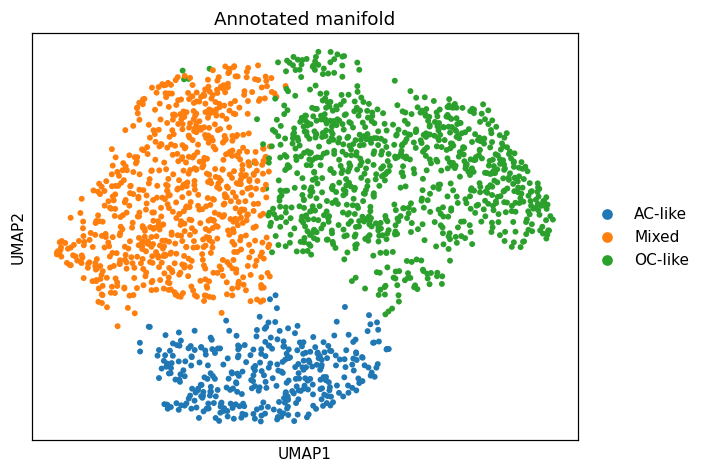

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print(adata)
sc.pl.umap(adata, color='celltype', size=60, title='Annotated manifold'); plt.show()

### Graph-smooth the embryonic signatures
Per the binding directive, topology and rooting are read off **smoothed** signatures (raw per-cell
scores are noise-dominated at this depth). Smooth via kNN-connectivity averaging.

In [ ]:
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg == 0] = 1
for k in ['Gast', 'pSom', 'Crest']:
    adata.obs[k + '_sm'] = (A @ adata.obs[k].values) / deg
print('smoothed Gast/pSom/Crest ranges:',
      {k: (round(adata.obs[k + '_sm'].min(), 2), round(adata.obs[k + '_sm'].max(), 2)) for k in ['Gast', 'pSom', 'Crest']})

smoothed Gast/pSom/Crest ranges: {'Gast': (np.float64(-0.26), np.float64(0.43)), 'pSom': (np.float64(-0.11), np.float64(0.53)), 'Crest': (np.float64(-0.2), np.float64(0.47))}


### Fit the PPT tree
`Nodes=40, ppt_lambda=3000, ppt_sigma=0.5` gives a clean **3-tip / 1-fork Y** (regularization tuned
up from the Puram default so the tree does not over-fragment the small manifold). The tree is fit on
the re-embedded `X_umap`, matching the reference protocol.

In [ ]:
scf.tl.tree(adata, method='ppt', Nodes=40, ppt_lambda=3000, ppt_sigma=0.5,
            use_rep='X_umap', seed=SEED, plot=False)
B = adata.uns['graph']['B']; d = B.sum(1)
tips = np.where(d == 1)[0]; forks = np.where(d > 2)[0]
print('tree: %d tips %d forks  ->  clean Y' % ((d == 1).sum(), (d > 2).sum()))
print('tip nodes:', tips.tolist(), '| fork node(s):', forks.tolist())

inferring a principal tree --> parameters used 
    40 principal points, sigma = 0.5, lambda = 3000, metric = euclidean
    fitting:   2%|2         | 1/50 [00:01<00:50,  1.04s/it]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
tree: 3 tips 1 forks  ->  clean Y
tip nodes: [5, 33, 36] | fork node(s): [37]


### Read the fork visually — tree edges on lineage & smoothed modules
The Y is obvious: a progenitor body forking into an **AC-like** arm and an **OC-like / Crest-high**
arm. Crest peaks at the OC arm *tip* (terminal readout), not at the origin.

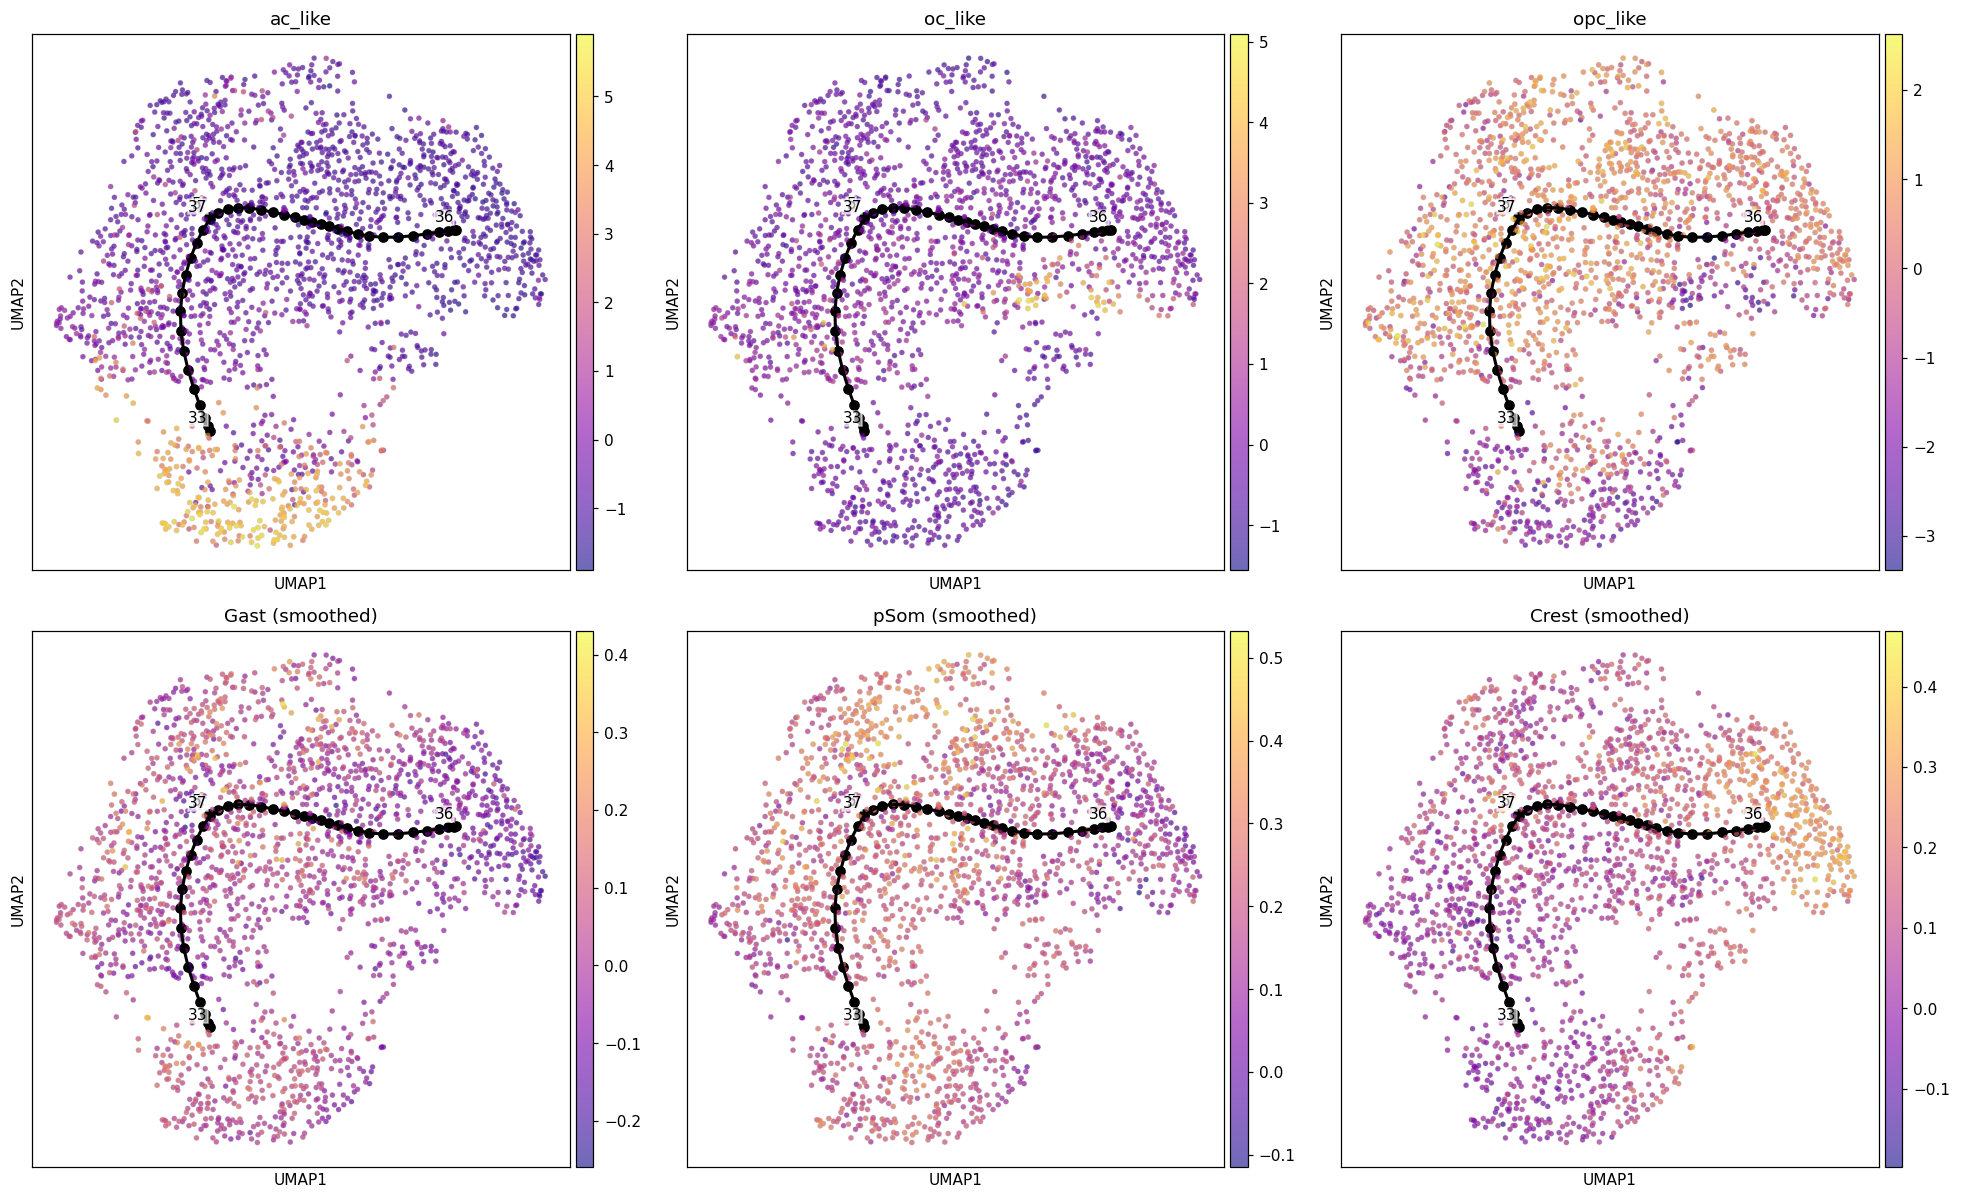

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(18, 11))
for ax, c in zip(axs.flat, ['ac_like', 'oc_like', 'opc_like', 'Gast_sm', 'pSom_sm', 'Crest_sm']):
    scf.pl.graph(adata, basis='umap', ax=ax, show=False)
    sc.pl.umap(adata, color=c, ax=ax, show=False, size=45, cmap='plasma', alpha=0.6)
    ax.set_title(c.replace('_sm', ' (smoothed)') if c.endswith('_sm') else c)
plt.tight_layout(); plt.show()

### Select the root by biological rule
Root = the tip that maximizes **(Gast + pSom) - Crest** on the smoothed signatures: the Gast/pSom-high,
Crest-low developmental origin. This is a **tip, not the fork/convergence node**, and explicitly not
the Crest-high tip (Crest is developmentally late). The rule is derived, shown, and non-circular.

In [ ]:
F = adata.uns['graph']['F']
rows = []
for t in tips:
    dd = np.linalg.norm(adata.obsm['X_umap'] - F[:, t], axis=1)
    o = adata.obs.iloc[np.argsort(dd)[:70]]
    rows.append(dict(tip=int(t), Gast=o.Gast_sm.mean(), pSom=o.pSom_sm.mean(), Crest=o.Crest_sm.mean(),
                     ac=o.ac_like.mean(), oc=o.oc_like.mean()))
tipdf = pd.DataFrame(rows)
tipdf['root_score'] = tipdf.Gast + tipdf.pSom - tipdf.Crest
print(tipdf.round(3).to_string(index=False))
root = int(tipdf.loc[tipdf.root_score.idxmax(), 'tip'])
crest_tip = int(tipdf.loc[tipdf.Crest.idxmax(), 'tip'])
print('ROOT = tip %d (Gast/pSom-high, Crest-low origin) | Crest-high terminal tip = %d (NOT root)' % (root, crest_tip))

 tip   Gast  pSom  Crest     ac    oc  root_score
   5  0.052 0.236  0.071 -0.572 0.188       0.216
  33 -0.034 0.229  0.027  0.077 0.475       0.168
  36 -0.032 0.176  0.159 -0.938 0.478      -0.015
ROOT = tip 5 (Gast/pSom-high, Crest-low origin) | Crest-high terminal tip = 36 (NOT root)


### Root, compute pseudotime, name milestones

In [ ]:
scf.tl.root(adata, root)
scf.tl.pseudotime(adata, n_jobs=4, seed=SEED)
# name milestones by role: root tip = Origin(Mixed-hub side); arms by dominant lineage; label from celltype majority
mil_ct = adata.obs.groupby('milestones', observed=True)['celltype'].agg(lambda s: s.value_counts().index[0])
mil_t = adata.obs.groupby('milestones', observed=True)['t'].mean()
print('milestone -> (dominant celltype, mean t):')
for m in mil_ct.index:
    print('  %s: %s  t=%.2f  n=%d' % (m, mil_ct[m], mil_t[m], (adata.obs.milestones == m).sum()))

node 5 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:01) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
milestone -> (dominant celltype, mean t):
  0: Mixed  t=1.87  n=257
  33: AC-like  t=2.45  n=380
  36: OC-like  t=4.97  n=711
  37: Mixed  t=1.20  n=541
  5: Mixed  t=0.01  n=109


renamed milestones: {'0': 'Mixed_2', '33': 'AC-like', '36': 'OC-like', '37': 'Mixed_1', '5': 'Mixed'}


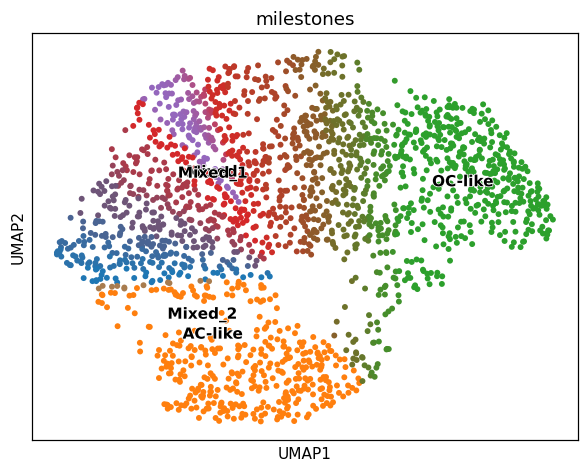

In [ ]:
# human-readable milestone names (root origin -> hub -> two arms)
order = mil_t.sort_values().index.tolist()
newnames = {}
for m in mil_ct.index:
    ct = mil_ct[m]
    nm = {'Mixed': 'Mixed', 'OPC-like': 'OPC-like', 'AC-like': 'AC-like', 'OC-like': 'OC-like'}.get(ct, ct)
    newnames[m] = nm
# ensure uniqueness (append pseudotime rank if collision)
seen = {}
for m in order:
    nm = newnames[m]
    if nm in seen:
        newnames[m] = f'{nm}_{seen[nm]}'; seen[nm] += 1
    else:
        seen[nm] = 1
scf.tl.rename_milestones(adata, new=newnames)
print('renamed milestones:', dict(newnames))
scf.pl.milestones(adata, basis='umap', annotate=True, s=60); plt.show()

### Save manifold

In [ ]:
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (1998, 21224)


### `manifold.pdf` — pseudotime trajectory with tree edges (Puram branching style)
Orientation matches the other panels (equivalent to inverting both axes) via a negated-coordinate
copy, so the `quiver` arrowheads are computed in display space and point *outward from the root*
(root -> tips). Inverting the axes after the arrows are drawn would reverse the arrowheads.

saved manifold.pdf | root tip 5 | arrows point outward from root


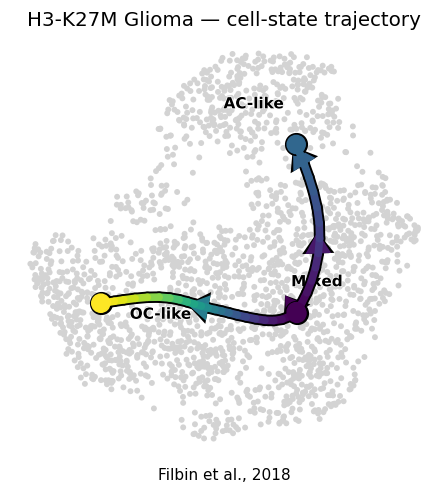

In [ ]:
adata_p = adata.copy(); adata_p.obsm['X_umap'] = -adata.obsm['X_umap']   # 180 deg view = both-axes inverted
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
scf.pl.trajectory(adata_p, basis='umap', arrows=True, ax=ax, show=False)
sc.pl.umap(adata_p, color='celltype', size=90, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.set_title('H3-K27M Glioma — cell-state trajectory', size=13)
ax.text(.5, -.05, 'Filbin et al., 2018', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.pdf | root tip', root, '| arrows point outward from root')